GitHub url: https://github.com/hagsetolav-lgtm/Deliverable_1.git 

Imports which we will use for the different tasks.

In [1]:
from pathlib import Path

from typing import Any
import requests 
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statistics import mean, median

import yaml

Reading our client ID's from local files exisiting outside of the repository.

In [2]:
id_file = Path.home() / "frost_client_id.txt"
client_id = id_file.read_text().strip()

Requesting the daily mean air temperatures for all of 2025.
We used the code prompt given to us in task 1 in the deliverable.
The request runs through all of 2025, and ends at the start of 2026.

In [3]:
endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2026-01-01",
    "timeoffsets": "default",
}


def get_observations(
        endpoint: str,
        parameters: dict[str, str],
        client_id: str, 
) -> list[dict[str, Any]]:
    """Collecting the observations from Frost

    Args:
        endpoint: the URL of the Frost observation endpoint.
        parameters: Filters the station
        client_id: ID used to verify and authenticate the request.

    Returns:
        A list of observations from Frost.
    """

    response = requests.get(
        endpoint,
        params=parameters, 
        auth=(client_id, ""),
        timeout=30,
    )
    response.raise_for_status()
    return response.json()["data"]

data = get_observations(endpoint, parameters, client_id)

print(f"Retrieved {len(data)} observation records from Frost.")
if data:
    print(data[0])

Retrieved 365 observation records from Frost.
{'sourceId': 'SN17850:0', 'referenceTime': '2025-01-01T00:00:00.000Z', 'observations': [{'elementId': 'mean(air_temperature P1D)', 'value': -5.2, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT0H', 'timeResolution': 'P1D', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 0}]}


Plotting and making summary table.
We select the temperatures by their IDs and convert the dates and values into Pyhton objects.
The line plot makes the change in daily mean air temperatures throughout the year clear.
The summary table includes the minimum and maximum daily mean air temperatures, aswell as 
the mean and median values.

In [4]:
def get_temperatures(
    data: list[dict[str, Any]],
) -> tuple[list[datetime], list[float]]:
    """Getting the dates and temperatures from the observations."""
    dates: list[datetime] = []
    temperatures: list[float] = []

    for record in sorted(data, key=lambda record: record["referenceTime"]):
        date = datetime.strptime(record["referenceTime"][:10], "%Y-%m-%d")

        for observation in record["observations"]:
            if observation["elementId"] == "mean(air_temperature P1D)":
                dates.append(date)
                temperatures.append(float(observation["value"]))

    return dates, temperatures


In [5]:
def plot_temperatures(
    dates: list[datetime],
    temperatures: list[float],
) -> None:
    """Plotting the mean air temperatures for Ås in 2025"""
    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(dates, temperatures, color="blue", linewidth=1)
    ax.set_title("Daily Mean Air Temperature in Ås, 2025")
    ax.set_xlabel("Month")
    ax.set_ylabel("Temperature (°C)")

    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()

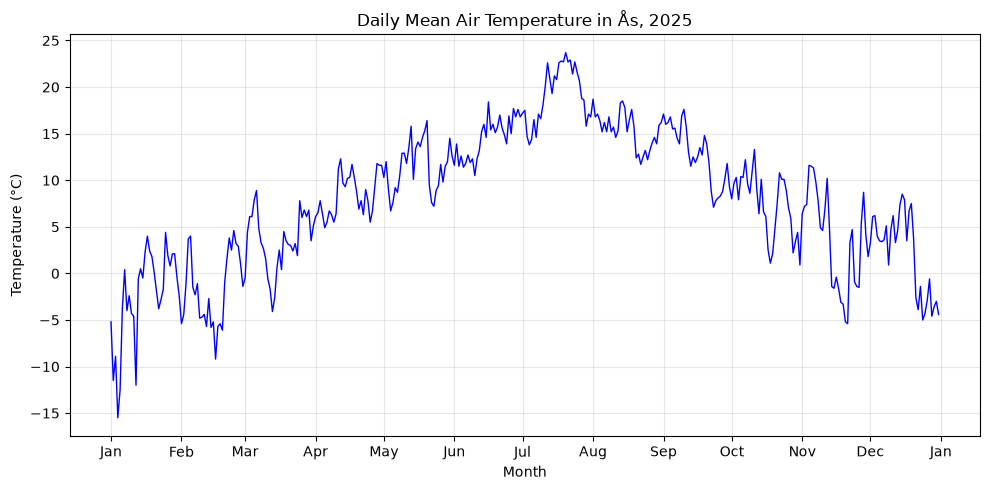

In [6]:
dates, temperatures = get_temperatures(data)
plot_temperatures(dates, temperatures)

In [7]:
def print_temperature_summary(temperatures: list[float]) -> None:
    """Printing the summary statistics for daily mean air tempertaures"""
    summary: dict[str, float] = {
        "Mean": mean(temperatures),
        "Minimum": min(temperatures),
        "Maximum": max(temperatures),
        "Median": median(temperatures),
    }

    print("Daily mean air tempertaures in Ås, 2025")
    print(f"{'Statistic':<12} {'Value':>12}")
    print("-" * 25)

    for statistic, value in summary.items():
        print(f"{statistic:<12} {value:>12.2f}")

In [8]:
print_temperature_summary(temperatures)

Daily mean air tempertaures in Ås, 2025
Statistic           Value
-------------------------
Mean                 7.87
Minimum            -15.50
Maximum             23.70
Median               8.30


The summary table shows the calculated mean air temperature values through the year, and the plot shows a typical temperature split, being cold in the winter and hotter in the summer.

Task 2: Precipitation

Setting up the request for precipitation over a 24 hour period, in millimetres.
Here we reuse the same parameters as Task 1.

In [9]:
precipitation_parameters: dict[str, str] = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2026-01-01",
    "timeoffsets": "default",
}

Getting the observations from Frost.

In [10]:
precipitation_data = get_observations(
    endpoint,
    precipitation_parameters,
    client_id,
)
print(f"Retrieved {len(precipitation_data)} precipitation records from Frost.")

if precipitation_data:
    print(precipitation_data[0])

Retrieved 365 precipitation records from Frost.
{'sourceId': 'SN17850:0', 'referenceTime': '2025-01-01T00:00:00.000Z', 'observations': [{'elementId': 'sum(precipitation_amount P1D)', 'value': 6.6, 'unit': 'mm', 'timeOffset': 'PT6H', 'timeResolution': 'P1D', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '2', 'qualityCode': 0}]}


Getting the precipitation dates and values from Frost, in chroological order.

In [11]:
precipitation_dates: list[datetime] = []
precipitation_values: list[float] = []

for record in sorted(precipitation_data, key=lambda record: record["referenceTime"]):
    date = datetime.strptime(record["referenceTime"][:10], "%Y-%m-%d")

    for observation in record["observations"]:
        if observation["elementId"] == "sum(precipitation_amount P1D)":
            precipitation_dates.append(date)
            precipitation_values.append(float(observation["value"]))

print(f"Extracted {len(precipitation_values)} precipitation values from the observations.")

Extracted 365 precipitation values from the observations.


Making the plot. Here we decided to use bars for precipitations, as it shows the accumulated amount per day. The line shows the variation in mean air temperatures. We also include to different veritcal lines, as the temperature and precipitation use two different measurements.

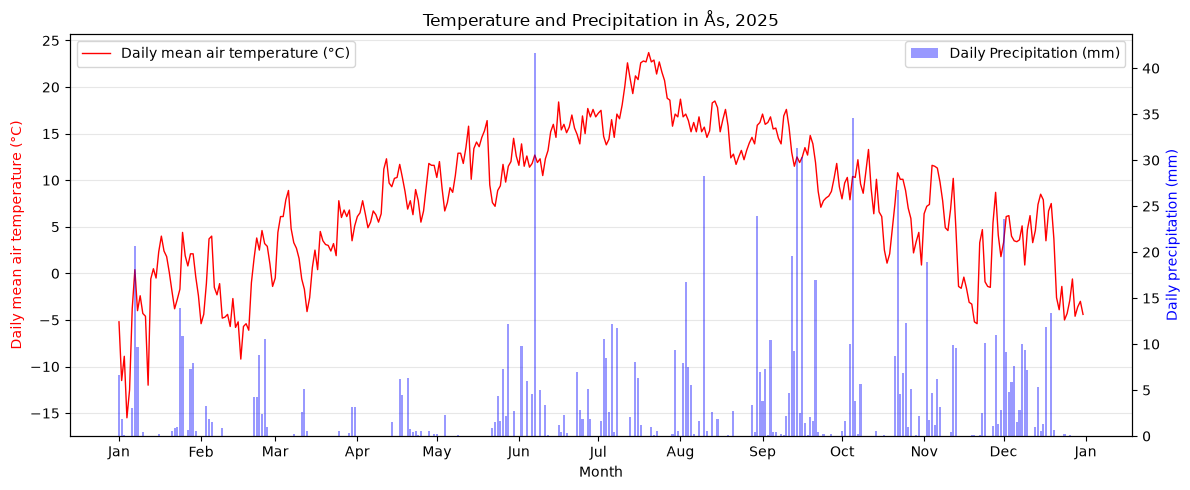

In [12]:
fig, ax_temperature = plt.subplots(figsize=(12, 5))
ax_precipitation = ax_temperature.twinx()

ax_precipitation.bar(
    precipitation_dates,
    precipitation_values,
    color="blue",
    alpha=0.4,
    label="Daily Precipitation (mm)",
)

ax_temperature.plot(
    dates,
    temperatures,
    color="red",
    linewidth=1.0,
    label="Daily mean air temperature (°C)",
)

ax_temperature.set_title("Temperature and Precipitation in Ås, 2025")
ax_temperature.set_xlabel("Month")
ax_temperature.set_ylabel("Daily mean air temperature (°C)", color="red")
ax_precipitation.set_ylabel("Daily precipitation (mm)", color="blue")
ax_precipitation.set_ylim(bottom=0)

ax_temperature.xaxis.set_major_locator(mdates.MonthLocator())
ax_temperature.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

ax_temperature.grid(axis="y", alpha=0.3)
ax_temperature.legend(loc="upper left")
ax_precipitation.legend(loc="upper right")

fig.tight_layout()
plt.show()

The temperature in the plots shows a seasonal progression, while the precipitation has more random values. 

Task 3: Historical temperature data.

Setting up the request for the old data (1925) using the same setup as for 2025.

In [13]:
historical_parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "1925-01-01/1926-01-01",
}

Getting the observations from Frost, using the same function as earlier, but now for 1925.


In [14]:
historical_data = get_observations(
    endpoint,
    historical_parameters,
    client_id
)
historical_dates, historical_temperatures = get_temperatures(
    historical_data
)

Comparing the years on the same plot, and aligning the values in the plot.

In [15]:
historical_plot_dates: list[datetime] = [
    date.replace(year=2025) 
    for date in historical_dates
]

Plotting them together. The two lines will show the patterns and differences in values.

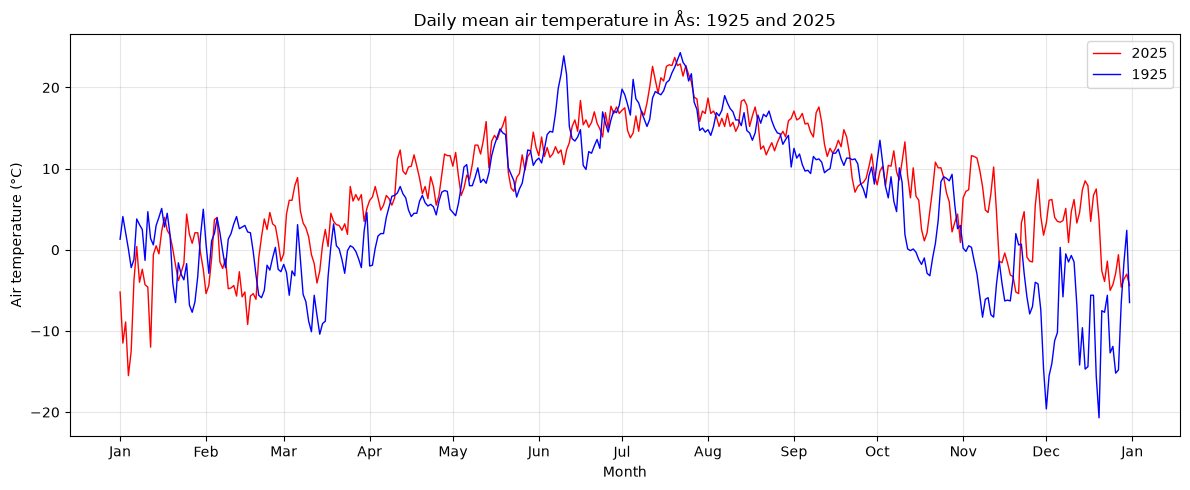

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    dates,
    temperatures,
    label="2025",
    color="red",
    linewidth=1.0,
)

ax.plot(
    historical_plot_dates,
    historical_temperatures,
    label="1925",
    color="blue",
    linewidth=1.0,
)

ax.set_title("Daily mean air temperature in Ås: 1925 and 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Air temperature (°C)")

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show() 

Summary table, including the mean, median, maximum and minimum values of the mean air temperatures.

In [17]:
def print_temperature_comparison(
        historical_temperatures: list[float],
        temperatures: list[float],
) -> None:
    """Printing the summary statistics for daily mean air tempertaures for Ås in 1925 and 2025."""
    comparison: dict[str, tuple[float, float]] = {
        "Mean": (mean(historical_temperatures), mean(temperatures)),
        "Minimum": (min(historical_temperatures), min(temperatures)),
        "Maximum": (max(historical_temperatures), max(temperatures)),
        "Median": (median(historical_temperatures), median(temperatures)),
    }

    print("Daily mean air tempertaures in Ås, 1925 and 2025")
    print(f"{'statistic':<12} {'1925':>12} {'2025':>12}")
    print("-" * 38)


    for statistic, (value_1925, value_2025) in comparison.items():
        print(f"{statistic:<12} {value_1925:>12.2f} {value_2025:>12.2f}")


In [18]:
print_temperature_comparison(historical_temperatures, temperatures)

Daily mean air tempertaures in Ås, 1925 and 2025
statistic            1925         2025
--------------------------------------
Mean                 5.28         7.87
Minimum            -20.70       -15.50
Maximum             24.30        23.70
Median               5.30         8.30


The two lines are relatively similar, but we can see that the winter in 1925 wa colder than the one in 2025.

Task 4: Heatwaves

Setting up the request.

In [19]:
heatwave_station_id: str = "SN17850"
heatwave_station_name: str = "Ås"
heatwave_year: int = 2025

heatwave_parameters: dict[str, str] = {
    "sources": heatwave_station_id,
    "elements": "max(air_temperature P1D)",
    "referencetime": (f"{heatwave_year}-01-01/{heatwave_year + 1}-01-01"),
    "timeoffsets": "default",
}

Getting the highest temperatures using the request funtion.

In [20]:
heatwave_data = get_observations(
    endpoint,
    heatwave_parameters,
    client_id,
)

print(f"Retrieved {len(heatwave_data)} records")

if heatwave_data:
    for observation in heatwave_data[0]["observations"]:
        print(observation)

Retrieved 365 records
{'elementId': 'max(air_temperature P1D)', 'value': -3, 'unit': 'degC', 'level': {'levelType': 'height_above_ground', 'unit': 'm', 'value': 2}, 'timeOffset': 'PT18H', 'timeResolution': 'P1D', 'timeSeriesId': 0, 'performanceCategory': 'C', 'exposureCategory': '1', 'qualityCode': 0}


Extract dates and highets temperatures.

In [21]:
heatwave_dates: list[datetime] = []
maximum_temperatures: list[float] = []

for record in sorted(heatwave_data, key=lambda record: record["referenceTime"]):
    date = datetime.strptime(record["referenceTime"][:10], "%Y-%m-%d")

    for observation in record["observations"]:
        if observation["elementId"] == "max(air_temperature P1D)":
            heatwave_dates.append(date)
            maximum_temperatures.append(float(observation["value"]))

print(f"Extracted {len(maximum_temperatures)} maximum temperatures from obervations.")
print(f"Unique dates: {len(set(heatwave_dates))}")
print(f"First date: {min(heatwave_dates):%Y-%m-%d}")
print(f"Last date: {max(heatwave_dates):%Y-%m-%d}")

Extracted 365 maximum temperatures from obervations.
Unique dates: 365
First date: 2025-01-01
Last date: 2025-12-31


Function to find heatwave periods. Thsi function will find periods that are defined as heatwaves, and will reset if a colder tmeperature happens.

In [22]:
def find_heatwaves(
    dates: list[datetime],
    temperatures: list[float],
) -> list[tuple[datetime, datetime]]:
    """Finding th eperiods with at least five consecutive days with maximum temperature at least 27°C."""
    if len(dates) != len(temperatures):
        raise ValueError("Each date must have a corresponding temperature value.")

    heatwaves: list[tuple[datetime, datetime]] = []
    current_streak: list[datetime] = []

    for date, temperature in sorted(zip(dates, temperatures)):
        if current_streak:
            gap = (date - current_streak[-1]).days

            if gap != 1 or temperature < 27:
                if len(current_streak) >= 5:
                    heatwaves.append((current_streak[0], current_streak[-1]))
                current_streak = []

        if temperature >= 27:
            current_streak.append(date)

    if len(current_streak) >= 5:
        heatwaves.append((current_streak[0], current_streak[-1]))

    return heatwaves

In [23]:
heatwaves = find_heatwaves(heatwave_dates, maximum_temperatures)
print(f"Number of heatwaves: {len(heatwaves)}")

for start, end in heatwaves:
    print(f"{start:%Y-%m-%d} - {end:%Y-%m-%d}")

Number of heatwaves: 1
2025-07-16 - 2025-07-22


The function identifies only one heatwave, happening between july the 16th, and july the 22nd.

Function for counting heatwaves and saving in yaml.

In [24]:
def save_heatwave_summary(
    dates: list[datetime],
    temperatures: list[float],
    station_id: str,
    station_name: str,
    year: int,
    output_file: str,
) -> int:
    """Saving heatwave date ranges for the year and returning the count.
    Temperatures must be daily maximum belonging to the station."""

    if len(dates) != len(temperatures):
        raise ValueError("Each date must have matching temperature")

    year_dates: list[datetime] = []
    year_temperatures: list[float] = []

    for date, temperature in zip(dates, temperatures):
        if date.year == year:
            year_dates.append(date)
            year_temperatures.append(temperature)

    if not year_dates:
        raise ValueError("No temperature data was supplied for {year}.")

    heatwaves = find_heatwaves(year_dates, year_temperatures)

    summary: dict[str, Any] = {
        "dates": [f"{start:%Y-%m-%d} - {end:%Y-%m-%d}" for start, end in heatwaves],
        "station_id": station_id,
        "station_name": station_name,
        "year": year,
    }

    with open(output_file, "w", encoding="utf-8") as file:
        yaml.safe_dump(
            summary,
            file,
            allow_unicode=True,
            sort_keys=False,
        )

    return(len(heatwaves))

In [25]:
heatwave_count = save_heatwave_summary(
    dates=heatwave_dates,
    temperatures=maximum_temperatures,
    station_id=heatwave_station_id,
    station_name=heatwave_station_name,
    year=heatwave_year,
    output_file="heatwave_summary_2025yml",
)

print(f"Saved summary for {heatwave_count} heatwave.")

Saved summary for 1 heatwave.


Task 5: Moving average temperature.

Defining the function.

In [26]:
def moving_average(temperatures: list[float]) -> list[float]:
    """Calculate the 7 day averages from consecutive daily temperatures.
    The first result will correspond to the seventh input day.
    Empty list returned if fewer than 7 values are supplied.
    """
    averages: list[float] = []

    for index in range(6, len(temperatures)):
        window = temperatures[index - 6:index + 1]
        averages.append(mean(window))

    return averages

Calculate the averages and match with dates.

In [27]:
average_temperatures: list[float] = moving_average(temperatures)
average_dates: list[datetime] = dates[6:]

print(f"Calculated {len(average_temperatures)} moving averages.")

Calculated 359 moving averages.


Plotting. The daily means are shown as dots, as individual observations. The line signifies the moving average value.


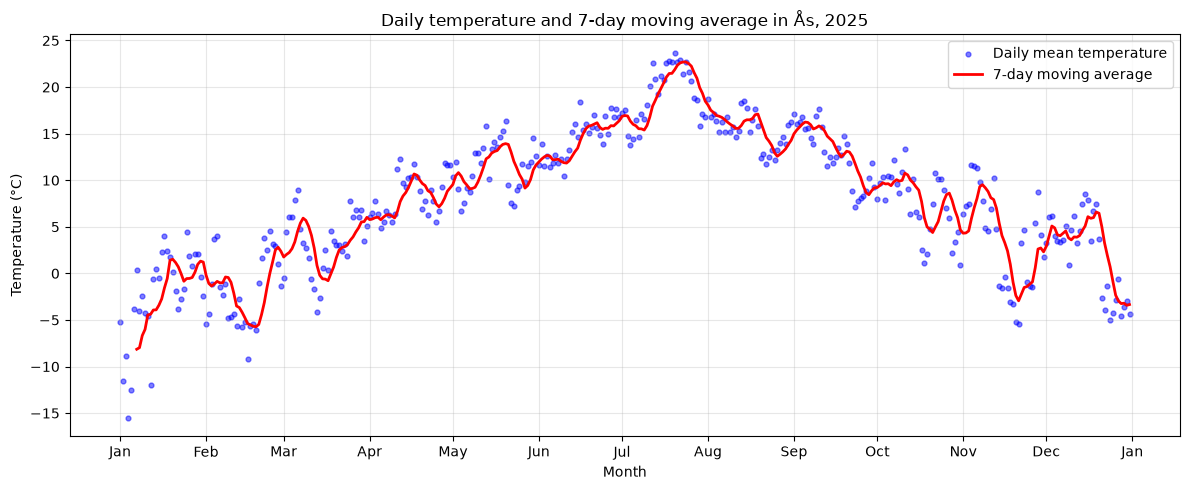

In [28]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(
    dates,
    temperatures,
    color="blue",
    s=12,
    alpha=0.5,
    label="Daily mean temperature",
)

ax.plot(
    average_dates,
    average_temperatures,
    color="red",
    linewidth=2,
    label="7-day moving average",
)

ax.set_title("Daily temperature and 7-day moving average in Ås, 2025")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()